In [1]:
# 1. Cài thư viện
!pip install -U transformers huggingface-hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 98.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 35.3 MB/s  0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [transformers]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


In [2]:
# 2. Import và cấu hình
import os, json
import pandas as pd
import torch
import transformers
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForTokenClassification, set_seed
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
from google.colab import drive
import shutil
from google.colab import files
drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/output_vtb"
SAVE_DIR = "/content/drive/MyDrive/phobert_pos5"
os.makedirs(SAVE_DIR, exist_ok=True)

MODEL_NAME = "vinai/phobert-base"
LABELS     = ["Noun", "Verb", "Adjective", "Adverb", "Other"]
label2id   = {lab: i for i, lab in enumerate(LABELS)}
id2label   = {i: lab for i, lab in enumerate(LABELS)}

BATCH_SIZE = 32      # theo Nguyen & Nguyen (2020)
LR         = 1e-5    # theo Nguyen & Nguyen (2020)
MAX_EPOCHS = 30      # theo Nguyen & Nguyen (2020)
PATIENCE   = 5       # dừng sớm sau 5 epoch không cải thiện
MAX_LEN    = 256     # giới hạn subword của PhoBERT

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if device == "cuda" else "không có (chạy bằng CPU)")
print("PyTorch", torch.__version__, "| Transformers", transformers.__version__)

Mounted at /content/drive
GPU: Tesla T4
PyTorch 2.14.1+cu130 | Transformers 5.24.0


In [3]:
# 3. Đọc dữ liệu và thống kê từng tập
def read_data(name):
    df = pd.read_csv(f"{DATA_DIR}/{name}_pos5.csv")
    words = df["tokens_phobert"].apply(json.loads).tolist()   # các từ của mỗi câu
    tags  = df["labels"].apply(json.loads).tolist()           # nhãn của từng từ
    assert all(len(w) == len(t) for w, t in zip(words, tags)), "Có câu số từ khác số nhãn"
    return words, tags

train_words, train_tags = read_data("train")
dev_words,   dev_tags   = read_data("dev")
test_words,  test_tags  = read_data("test")

stats = []
for name, words, tags in [("Train", train_words, train_tags), ("Dev", dev_words, dev_tags), ("Test", test_words, test_tags)]:
    lengths  = [len(w) for w in words]
    all_tags = [t for sent in tags for t in sent]
    row = {"Tập": name, "Số câu": len(words), "Số từ": sum(lengths),
           "Từ/câu TB": round(sum(lengths) / len(words), 2), "Dài nhất": max(lengths)}
    for lab in LABELS:
        row[lab] = all_tags.count(lab)
    stats.append(row)
print(pd.DataFrame(stats).to_string(index=False))

  Tập  Số câu  Số từ  Từ/câu TB  Dài nhất  Noun  Verb  Adjective  Adverb  Other
Train    1389  16590      11.94        23  6467  4284       1095    1478   3266
  Dev    1121  21645      19.31        78  8859  5469       1561    1641   4115
 Test     793   9685      12.21        23  3561  2376        719    1020   2009


In [4]:
# 4. Tokenizer và căn chỉnh nhãn: subword đầu của mỗi từ mang nhãn, các vị trí còn lại là -100
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(words, tags):
    ids, labels = [tokenizer.cls_token_id], [-100]                  # <s>
    for word, tag in zip(words, tags):
        pieces = tokenizer.encode(word, add_special_tokens=False) or [tokenizer.unk_token_id]
        ids    += pieces
        labels += [label2id[tag]] + [-100] * (len(pieces) - 1)
    ids.append(tokenizer.sep_token_id)                              # </s>
    labels.append(-100)
    return ids, labels

train_data = [encode(w, t) for w, t in zip(train_words, train_tags)]
dev_data   = [encode(w, t) for w, t in zip(dev_words, dev_tags)]
test_data  = [encode(w, t) for w, t in zip(test_words, test_tags)]

# Kiểm tra: mỗi từ có đúng 1 nhãn và không câu nào vượt 256 subword
for name, data, words in [("Train", train_data, train_words), ("Dev", dev_data, dev_words), ("Test", test_data, test_words)]:
    n_labels = sum(sum(l != -100 for l in labs) for _, labs in data)
    longest  = max(len(ids) for ids, _ in data)
    print(f"{name}: {n_labels} nhãn / {sum(len(w) for w in words)} từ | câu dài nhất {longest} subword")
    assert longest <= MAX_LEN, "Có câu vượt quá 256 subword"

# Ví dụ căn chỉnh cho câu train_00002
ids, labels = train_data[1]
for token, lab in zip(tokenizer.convert_ids_to_tokens(ids), labels):
    print(f"{token:15} {id2label.get(lab, '-100')}")

config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Train: 16590 nhãn / 16590 từ | câu dài nhất 40 subword
Dev: 21645 nhãn / 21645 từ | câu dài nhất 86 subword
Test: 9685 nhãn / 9685 từ | câu dài nhất 31 subword
<s>             -100
Hiện_nay        Noun
xã              Noun
có              Verb
tổ              Noun
nhân_dân        Noun
tổ              Noun
phụ_trách       Verb
gia_đình        Noun
</s>            -100


In [5]:
# 5. DataLoader: gom 32 câu thành 1 batch, đệm câu ngắn bằng <pad>
def collate(batch):
    max_len = max(len(ids) for ids, _ in batch)
    input_ids, mask, labels = [], [], []
    for ids, labs in batch:
        n_pad = max_len - len(ids)
        input_ids.append(ids + [tokenizer.pad_token_id] * n_pad)
        mask.append([1] * len(ids) + [0] * n_pad)                   # 1 = token thật, 0 = token đệm
        labels.append(labs + [-100] * n_pad)
    return torch.tensor(input_ids), torch.tensor(mask), torch.tensor(labels)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
dev_loader   = DataLoader(dev_data,   batch_size=BATCH_SIZE, collate_fn=collate)
test_loader  = DataLoader(test_data,  batch_size=BATCH_SIZE, collate_fn=collate)

In [6]:
# 6. Khởi tạo mô hình: PhoBERT-base + lớp phân loại Linear 768 -> 5
# Cảnh báo về lm_head (không dùng) và classifier (khởi tạo mới) khi tải mô hình là bình thường
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id).to(device)

print(model.classifier)
print("Tổng số tham số:", sum(p.numel() for p in model.parameters()))
print("Số tham số lớp phân loại:", sum(p.numel() for p in model.classifier.parameters()))

optimizer = torch.optim.AdamW(model.parameters(), lr=LR)       # weight decay mặc định 0.01

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForTokenClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=5, bias=True)
Tổng số tham số: 134411525
Số tham số lớp phân loại: 3845


In [7]:
# 7. Hàm đánh giá: chỉ chấm ở subword đầu của mỗi từ (nhãn khác -100)
def evaluate(loader):
    model.eval()
    total_loss, y_true, y_pred = 0, [], []
    with torch.no_grad():
        for input_ids, mask, labels in loader:
            input_ids, mask, labels = input_ids.to(device), mask.to(device), labels.to(device)
            out = model(input_ids=input_ids, attention_mask=mask, labels=labels)
            total_loss += out.loss.item()
            keep = labels != -100
            y_true += labels[keep].tolist()
            y_pred += out.logits.argmax(dim=-1)[keep].tolist()
    acc      = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, labels=list(range(len(LABELS))), average="macro", zero_division=0)
    return total_loss / len(loader), acc, macro_f1, y_true, y_pred

In [8]:
# 8. Huấn luyện: theo dõi loss, lưu mô hình có Accuracy trên Dev cao nhất, dừng sớm
history = []
best_acc, wait = 0, 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    total_loss = 0
    for input_ids, mask, labels in train_loader:
        input_ids, mask, labels = input_ids.to(device), mask.to(device), labels.to(device)
        out = model(input_ids=input_ids, attention_mask=mask, labels=labels)   # dự đoán + tính loss
        optimizer.zero_grad()
        out.loss.backward()                                                   # lan truyền ngược
        optimizer.step()                                                      # cập nhật trọng số
        total_loss += out.loss.item()

    train_loss = total_loss / len(train_loader)
    dev_loss, dev_acc, dev_f1, _, _ = evaluate(dev_loader)
    history.append([epoch, train_loss, dev_loss, dev_acc, dev_f1])
    print(f"Epoch {epoch:2d} | train loss {train_loss:.4f} | dev loss {dev_loss:.4f} "
          f"| dev accuracy {dev_acc:.4f} | dev macro-F1 {dev_f1:.4f}")

    if dev_acc > best_acc:
        best_acc, best_epoch, wait = dev_acc, epoch, 0
        model.save_pretrained(SAVE_DIR)
        tokenizer.save_pretrained(SAVE_DIR)
        print("   -> lưu mô hình tốt nhất")
    else:
        wait += 1
        if wait == PATIENCE:
            print(f"Dừng sớm: {PATIENCE} epoch liền Accuracy trên Dev không tăng")
            break

history = pd.DataFrame(history, columns=["epoch", "train_loss", "dev_loss", "dev_accuracy", "dev_macro_f1"])
history.to_csv(f"{SAVE_DIR}/training_log.csv", index=False)
print(f"Mô hình tốt nhất ở epoch {best_epoch}, Accuracy trên Dev = {best_acc:.4f}")

Epoch  1 | train loss 1.3286 | dev loss 1.1105 | dev accuracy 0.6835 | dev macro-F1 0.4254


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> lưu mô hình tốt nhất
Epoch  2 | train loss 0.8430 | dev loss 0.5606 | dev accuracy 0.8295 | dev macro-F1 0.6692


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> lưu mô hình tốt nhất
Epoch  3 | train loss 0.4684 | dev loss 0.3657 | dev accuracy 0.8931 | dev macro-F1 0.8408


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (19 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> lưu mô hình tốt nhất
Epoch 19 | train loss 0.0725 | dev loss 0.2592 | dev accuracy 0.9262 | dev macro-F1 0.8977


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> lưu mô hình tốt nhất
Epoch 20 | train loss 0.0698 | dev loss 0.2792 | dev accuracy 0.9226 | dev macro-F1 0.8943
Epoch 21 | train loss 0.0621 | dev loss 0.2742 | dev accuracy 0.9239 | dev macro-F1 0.8949
Epoch 22 | train loss 0.0577 | dev loss 0.2807 | dev accuracy 0.9241 | dev macro-F1 0.8966
Epoch 23 | train loss 0.0533 | dev loss 0.2817 | dev accuracy 0.9257 | dev macro-F1 0.8991
Epoch 24 | train loss 0.0493 | dev loss 0.2766 | dev accuracy 0.9259 | dev macro-F1 0.8980
Dừng sớm: 5 epoch liền Accuracy trên Dev không tăng
Mô hình tốt nhất ở epoch 19, Accuracy trên Dev = 0.9262


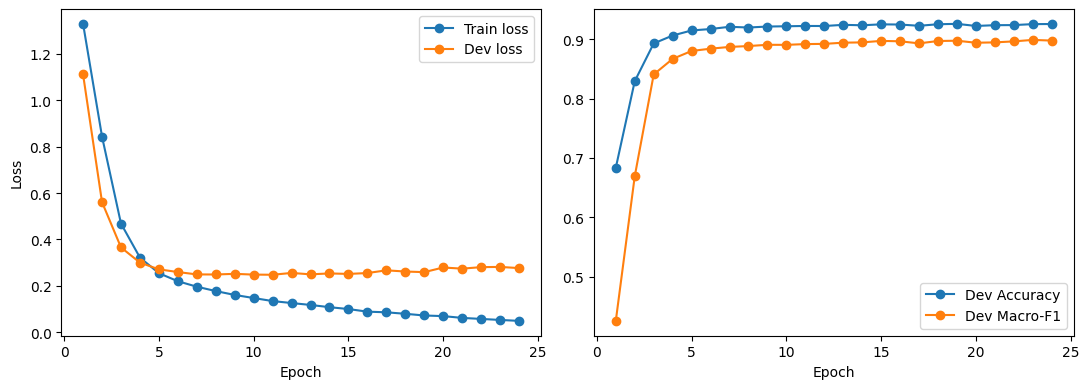

In [9]:
# 9. Biểu đồ loss và chỉ số trên Dev theo epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history["epoch"], history["train_loss"], marker="o", label="Train loss")
ax1.plot(history["epoch"], history["dev_loss"], marker="o", label="Dev loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend()
ax2.plot(history["epoch"], history["dev_accuracy"], marker="o", label="Dev Accuracy")
ax2.plot(history["epoch"], history["dev_macro_f1"], marker="o", label="Dev Macro-F1")
ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/training_curves.png", dpi=150)
plt.show()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Accuracy 0.9331 | Macro-F1 0.9101 | Weighted-F1 0.9328
              precision    recall  f1-score   support

        Noun     0.9611    0.9708    0.9659      3561
        Verb     0.9267    0.9314    0.9291      2376
   Adjective     0.8430    0.7914    0.8164       719
      Adverb     0.8847    0.9255    0.9046      1020
       Other     0.9469    0.9228    0.9347      2009

    accuracy                         0.9331      9685
   macro avg     0.9125    0.9084    0.9101      9685
weighted avg     0.9329    0.9331    0.9328      9685



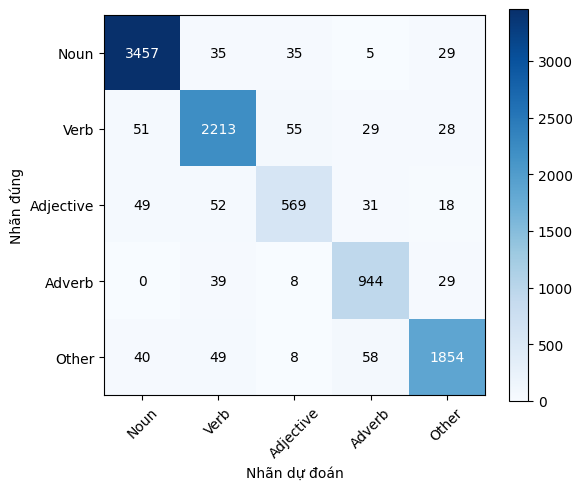

In [10]:
# 10. Đánh giá mô hình tốt nhất trên tập Test (số liệu cho Chương 4)
model = AutoModelForTokenClassification.from_pretrained(SAVE_DIR).to(device)
test_loss, test_acc, test_f1, y_true, y_pred = evaluate(test_loader)
weighted_f1 = f1_score(y_true, y_pred, labels=list(range(len(LABELS))), average="weighted", zero_division=0)
print(f"Accuracy {test_acc:.4f} | Macro-F1 {test_f1:.4f} | Weighted-F1 {weighted_f1:.4f}")
print(classification_report(y_true, y_pred, labels=list(range(len(LABELS))), target_names=LABELS, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(LABELS))))
pd.DataFrame(cm, index=LABELS, columns=LABELS).to_csv(f"{SAVE_DIR}/confusion_matrix.csv")
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(LABELS)), LABELS, rotation=45)
plt.yticks(range(len(LABELS)), LABELS)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Nhãn dự đoán"); plt.ylabel("Nhãn đúng"); plt.colorbar()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/confusion_matrix.png", dpi=150)
plt.show()

# Lưu nhãn đúng và nhãn dự đoán của từng từ để phân tích lỗi
rows = [[i, w, t] for i, (ws, ts) in enumerate(zip(test_words, test_tags), start=1) for w, t in zip(ws, ts)]
result = pd.DataFrame(rows, columns=["cau", "tu", "nhan_dung"])
result["nhan_du_doan"] = [id2label[p] for p in y_pred]
result.to_csv(f"{SAVE_DIR}/test_predictions.csv", index=False)

In [11]:
# Xuất model
m = AutoModelForTokenClassification.from_pretrained(SAVE_DIR)
m.config.label2id, m.config.id2label = label2id, id2label
m.save_pretrained("/content/model")
AutoTokenizer.from_pretrained(SAVE_DIR).save_pretrained("/content/model")
shutil.make_archive("/content/model", "zip", "/content/model")
files.download("/content/model.zip")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>